In [26]:
import pandas
import seaborn
import numpy
import warnings
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.preprocessing import Normalizer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error, r2_score

aggpops = pandas.read_csv('aggdata/aggpops_transposed(Sheet1).csv')
aggpops.head(15)

,Year,Groningen,Fryslân,Drenthe,Overijssel,Flevoland,Gelderland,Utrecht,Noord-Holland,Zuid-Holland,...,Västra Götaland county,Värmland county,Örebro county,Västmanland county,Dalarna county,Gävleborg county,Västernorrland county,Jämtland county,Västerbotten county,Norrbotten county
0,1942,430271,433541,252367,591063,NaN,951527,497397,1701855,2171832,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1943,432670,436786,261098,598904,NaN,970296,503304,1694657,2162322,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1944,436936,444017,269284,612744,NaN,1003125,513904,1660816,2121548,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1945,441157,452043,264875,620175,NaN,1017876,523605,1671692,2122582,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1946,442462,453109,266524,623616,NaN,1003481,524942,1692390,2161419,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1947,447427,456623,269769,633558,NaN,1019779,544656,1759499,2256454,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1948,453057,460519,273800,644492,NaN,1039025,556391,1794070,2308382,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,1949,457611,463442,277258,656047,NaN,1057941,565662,1824305,2351669,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1950,459819,465267,280798,670030,NaN,1077612,573422,1842604,2382898,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1951,461802,467731,285079,682235,NaN,1100976,584176,1874557,2424581,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
aggpops.describe()

,Year,Groningen,Fryslân,Drenthe,Overijssel,Flevoland,Gelderland,Utrecht,Noord-Holland,Zuid-Holland,...,Västra Götaland county,Värmland county,Örebro county,Västmanland county,Dalarna county,Gävleborg county,Västernorrland county,Jämtland county,Västerbotten county,Norrbotten county
count,83.000000,83.000000,83.000000,83.000000,8.300000e+01,39.000000,8.300000e+01,8.300000e+01,8.300000e+01,8.300000e+01,...,5.700000e+01,57.000000,57.000000,57.000000,57.000000,57.000000,57.000000,57.000000,57.000000,57.000000
mean,1983.000000,531735.180723,565271.313253,402387.975904,9.555683e+05,336106.487179,1.638074e+06,9.310933e+05,2.329031e+06,3.075315e+06,...,1.504498e+06,280129.122807,279803.017544,260856.350877,282634.859649,286099.473684,254724.912281,131668.578947,253640.859649,257507.280702
std,24.103942,49241.332848,73739.736357,81126.006733,1.772726e+05,82553.169552,3.600711e+05,2.621373e+05,3.372866e+05,4.559907e+05,...,1.252935e+05,4435.137134,11507.573041,7718.260066,4967.468065,6444.395902,10495.965288,3249.788570,12563.158815,6823.355824
min,1942.000000,430271.000000,433541.000000,252367.000000,5.910630e+05,177334.000000,9.515270e+05,4.973970e+05,1.660816e+06,2.121548e+06,...,1.333196e+06,272736.000000,269341.000000,248489.000000,275618.000000,275556.000000,241458.000000,126201.000000,232856.000000,248480.000000
25%,1962.500000,483859.000000,485111.500000,322068.000000,8.155645e+05,267584.000000,1.326880e+06,7.031675e+05,2.111209e+06,2.771424e+06,...,1.391774e+06,275003.000000,273608.000000,256889.000000,277349.000000,279991.000000,244105.000000,128586.000000,245055.000000,250497.000000
50%,1983.000000,555200.000000,595248.000000,424720.000000,1.014949e+06,365859.000000,1.727487e+06,9.231820e+05,2.311534e+06,3.129913e+06,...,1.485014e+06,282115.000000,274325.000000,259670.000000,283350.000000,287382.000000,256587.000000,132542.000000,255987.000000,257332.000000
75%,2003.500000,573228.000000,640926.500000,481834.500000,1.103094e+06,400842.000000,1.963676e+06,1.157238e+06,2.580192e+06,3.445962e+06,...,1.580297e+06,284011.000000,280230.000000,261391.000000,286667.000000,292021.000000,266038.000000,134561.000000,259895.000000,264320.000000
max,2024.000000,601347.000000,661904.000000,504129.000000,1.189033e+06,450826.000000,2.149071e+06,1.400057e+06,2.976487e+06,3.840460e+06,...,1.772821e+06,285498.000000,308375.000000,281158.000000,291203.000000,294627.000000,269516.000000,136301.000000,281138.000000,267648.000000


In [27]:
aggpops['Year'] = pandas.to_datetime(aggpops['Year'], format='%Y')
aggpops.set_index('Year', inplace=True)
aggpops = aggpops.asfreq('YS')

# aggpops = aggpops.fillna(-1)

aggpops.head(10)

,Groningen,Fryslân,Drenthe,Overijssel,Flevoland,Gelderland,Utrecht,Noord-Holland,Zuid-Holland,Zeeland,...,Västra Götaland county,Värmland county,Örebro county,Västmanland county,Dalarna county,Gävleborg county,Västernorrland county,Jämtland county,Västerbotten county,Norrbotten county
Year,,,,,,,,,,,,,,,,,,,,,
1942-01-01,430271,433541,252367,591063,NaN,951527,497397,1701855,2171832,256131,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1943-01-01,432670,436786,261098,598904,NaN,970296,503304,1694657,2162322,257922,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1944-01-01,436936,444017,269284,612744,NaN,1003125,513904,1660816,2121548,256459,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1945-01-01,441157,452043,264875,620175,NaN,1017876,523605,1671692,2122582,227596,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1946-01-01,442462,453109,266524,623616,NaN,1003481,524942,1692390,2161419,252483,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1947-01-01,447427,456623,269769,633558,NaN,1019779,544656,1759499,2256454,258510,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1948-01-01,453057,460519,273800,644492,NaN,1039025,556391,1794070,2308382,262589,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-01-01,457611,463442,277258,656047,NaN,1057941,565662,1824305,2351669,265759,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1950-01-01,459819,465267,280798,670030,NaN,1077612,573422,1842604,2382898,268609,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [28]:
warnings.filterwarnings('ignore')

# if using slicing
hgsearchfeatures = aggpops.loc['2001-01-01':'2024-01-01', :].iloc[:-1]
hgsearchtarget = aggpops.loc['2001-01-01':'2024-01-01', :].shift(-1).iloc[:-1]

# if using fillna
# hgsearchfeatures = aggpops.iloc[:-1]
# hgsearchtarget = aggpops.shift(-1).iloc[:-1]

timesplit = TimeSeriesSplit(n_splits=2)

for fold, (train_idx, test_idx) in enumerate(timesplit.split(hgsearchfeatures), start=1):
    X_train, X_test = hgsearchfeatures.iloc[train_idx].values.reshape(-1,1), hgsearchfeatures.iloc[test_idx].values.reshape(-1,1)
    y_train, y_test = hgsearchtarget.iloc[train_idx].values.reshape(-1,1), hgsearchtarget.iloc[test_idx].values.reshape(-1,1)

In [15]:
mlpparams = {
    'hidden_layer_sizes': [50, 100, 150, 200],
    'activation': ['tanh', 'relu'],
    'solver': ['adam', 'lbfgs'],
    'early_stopping': [True],
    'momentum': [0.3, 0.5, 0.7, 0.9]
}

knnparams = {
    'n_neighbors': [5, 10, 15, 20, 25],
    'weights': ['uniform', 'distance'],
    'algorithm': ['ball_tree', 'kd_tree', 'brute'],
    'leaf_size': [0, 10, 30, 50, 70]
}

rfparams = {
    'n_estimators': [100, 200, 300, 400],
    'criterion': ['squared_error', 'absolute_error', 'friedman_mse'],
    'bootstrap': [False, True],
    'warm_start': [True, False]
}

testing_models = {
    'MLP': MLPRegressor(),
    'KNN': KNeighborsRegressor(),
    'RF': RandomForestRegressor()
}

test_results = {}

def g_search(test_model, test_params):
    search = GridSearchCV(
        estimator=test_model,
        param_grid=test_params,
        cv=timesplit,
        n_jobs=2,
        verbose=1
    )

    search.fit(hgsearchfeatures, hgsearchtarget)
    test_results[str(testing_models['MLP'])] = search.best_params_

g_search(testing_models['MLP'], mlpparams)
g_search(testing_models['KNN'], knnparams)
g_search(testing_models['RF'], rfparams)

Fitting 2 folds for each of 64 candidates, totalling 128 fits
{'activation': 'tanh', 'early_stopping': True, 'hidden_layer_sizes': 150, 'momentum': 0.3, 'solver': 'lbfgs'}


In [29]:
brf = RandomForestRegressor(
    criterion='absolute_error',
    n_estimators=200,
    bootstrap=False,
    warm_start=True
)

ensemble = StackingRegressor(
    estimators=[
    ('mlp', MLPRegressor(
        hidden_layer_sizes=2000,
        solver='lbfgs',
        learning_rate='adaptive',
        activation='tanh',
        early_stopping=True,
        momentum=0.7
        )
    ),
        
    ('knn', KNeighborsRegressor(
        algorithm='ball_tree',
        leaf_size=10,
        n_neighbors=5,
        weights='distance'
        ))
    ],
    final_estimator=LinearRegression(),
    n_jobs=2,
    passthrough=True
)

algos = [brf, ensemble]

for algo in algos:
    algo.fit(X_train, y_train)

brf_ypred, ens_ypred = (algo.predict(X_test) for algo in algos)

In [30]:
results = {
    'stackingensemble': ens_ypred,
    'randomforest': brf_ypred
}

rmse = {}
mae = {}
mape = {}
r2 = {}

metrics = [rmse, mae, mape, r2]

for algo, preds in results.items():
    rmse[f'{algo}'] = root_mean_squared_error(y_test, preds)
    mae[f'{algo}'] = mean_absolute_error(y_test, preds)
    mape[f'{algo}'] = mean_absolute_percentage_error(y_test, preds)
    r2[f'{algo}'] = r2_score(y_test, preds)

metricsdf = pandas.DataFrame({
    'model': list(rmse.keys()),
    'RMSE': list(rmse.values()),
    'MAE':  list(mae.values()),
    'MAPE': list(mape.values()),
    'R2':   list(r2.values())
})

for algo, preds in results.items():
    print(f'''
    RMSE:
    {algo}: {root_mean_squared_error(y_test, preds)}

    MAE:
    {algo}: {mean_absolute_error(y_test, preds)}    

    MAPE:
    {algo}: {mean_absolute_percentage_error(y_test, preds)}

    R2:
    {algo}: {r2_score(y_test, preds)}
    
    ''')


    RMSE:
    stackingensemble: 18454.809109470883

    MAE:
    stackingensemble: 7877.371110718869    

    MAPE:
    stackingensemble: 0.0077207632238509875

    R2:
    stackingensemble: 0.9998934962177863

    

    RMSE:
    randomforest: 63518.4936006802

    MAE:
    randomforest: 21813.06968641115    

    MAPE:
    randomforest: 0.011560658743950448

    R2:
    randomforest: 0.9987383284911209

    


In [19]:
joblib.dump(ensemble, 'revised-stackensemble')
joblib.dump(brf, 'revised-randforest')

['revised-randforest']

<Axes: xlabel='model', ylabel='RMSE'>

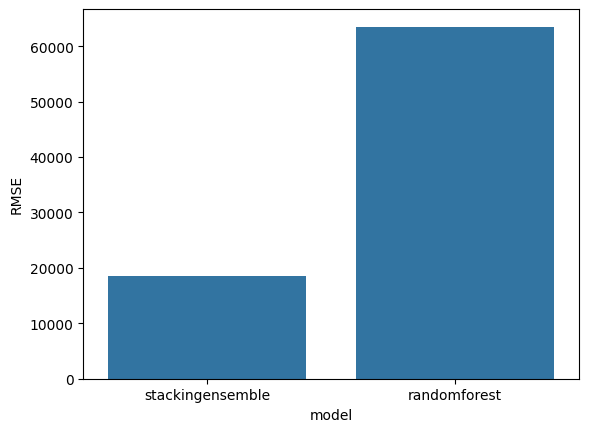

In [15]:
seaborn.barplot(data=metricsdf, x='model', y='RMSE')

<Axes: xlabel='model', ylabel='MAE'>

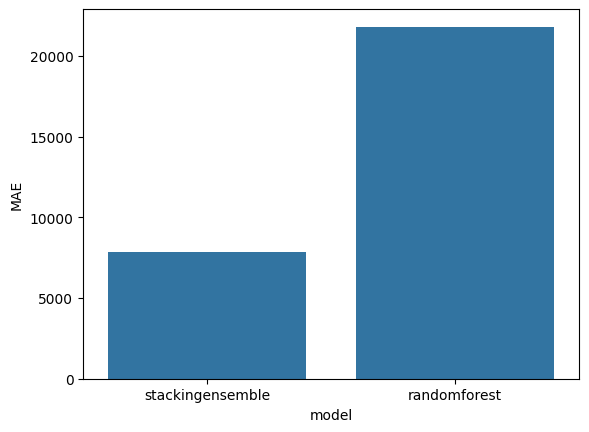

In [18]:
seaborn.barplot(data=metricsdf, x='model', y='MAE')

<Axes: xlabel='model', ylabel='MAPE'>

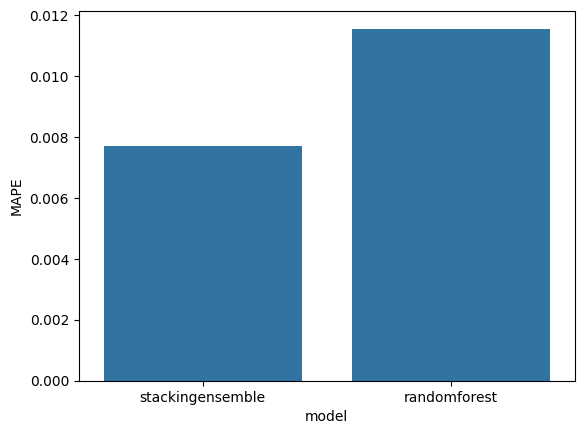

In [17]:
seaborn.barplot(data=metricsdf, x='model', y='MAPE')

<Axes: xlabel='model', ylabel='R2'>

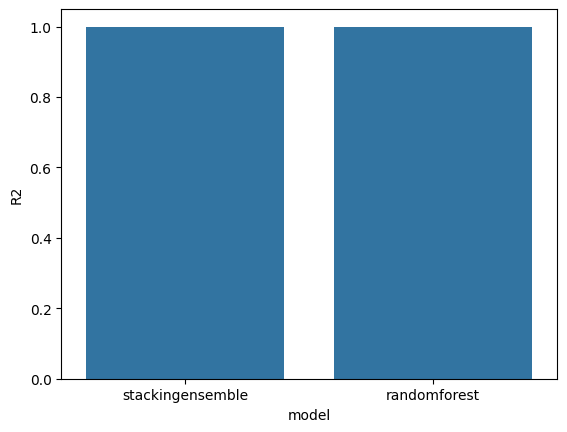

In [16]:
seaborn.barplot(data=metricsdf, x='model', y='R2')